## Task 1: Real-World Data Ingestion & Validation
Load and validate the genuine agroclimatology and historical crop yield dataset (2001–2022) across Punjab, Sindh, and Balochistan.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option("display.max_columns", 30)
print("Libraries loaded successfully.")

In [ ]:
PROJECT_ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
print(f"Project root: {PROJECT_ROOT}")

data_path = PROJECT_ROOT / "data/raw/pakistan_crop_yield_climate.parquet"
if not data_path.exists():
    data_path = PROJECT_ROOT / "data/raw/pakistan_crop_yield_climate.csv"

df = pd.read_parquet(data_path) if data_path.suffix == ".parquet" else pd.read_csv(data_path)
print(f"Loaded dataset: {df.shape[0]:,} rows, {df.shape[1]} columns")

In [ ]:
assert df.shape == (10296, 19), f"Unexpected shape: {df.shape}"
print("Shape assertion passed: 10,296 rows, 19 columns.")
print()
print("Dataset Columns and Types:")
print(df.dtypes)

In [ ]:
missing_counts = df.isnull().sum()
print("Missing values per column:")
print(missing_counts[missing_counts > 0] if (missing_counts > 0).any() else "No missing values found across all columns.")
assert missing_counts.sum() == 0, "Missing values detected in raw data!"

In [ ]:
crop_stats = df.groupby("Crop").agg(
    Observations=("Yield", "count"),
    Min_Yield=("Yield", "min"),
    Max_Yield=("Yield", "max"),
    Mean_Yield=("Yield", "mean"),
    Std_Yield=("Yield", "std"),
    Mean_Precipitation=("precipitation_sum", "mean"),
    Mean_Evapotranspiration=("fao_evapotranspiration", "mean"),
).reset_index().sort_values("Mean_Yield")

print("Crop Yield & Climate Statistics (Real Historical Variance):")
print(crop_stats.to_string(index=False))

DROUGHT_RESILIENT_CROPS = ["dates", "grapes", "pomegranate", "wheat", "onion"]
WATER_INTENSIVE_CROPS = ["sugarcane", "rice", "banana", "cotton"]

df["Is_Drought_Resilient"] = df["Crop"].isin(DROUGHT_RESILIENT_CROPS)
print()
print(f"Drought-resilient / lower-water crops: {DROUGHT_RESILIENT_CROPS}")
print(f"Water-intensive crops: {WATER_INTENSIVE_CROPS}")


---
## Task 2: Exploratory Data Analysis (EDA)
Fulfilling the CT-378 rubric requirement of at least 5 analytical visualizations:
1. **Yield Distribution by Crop** (Drought-resilient vs. water-intensive crops)
2. **Rainfall Deficit vs. Crop Yield** (Yield response curves under water deficit)
3. **Drought Severity Class Frequency & Mean Yield Impact**
4. **Feature Correlation Heatmap** (Climate, drought indices, and irrigation)
5. **Water Regimes & Irrigation Breakdown by Province**

In [6]:
sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams["figure.dpi"] = 120
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
print("Plot styling configured.")

Plot styling configured.


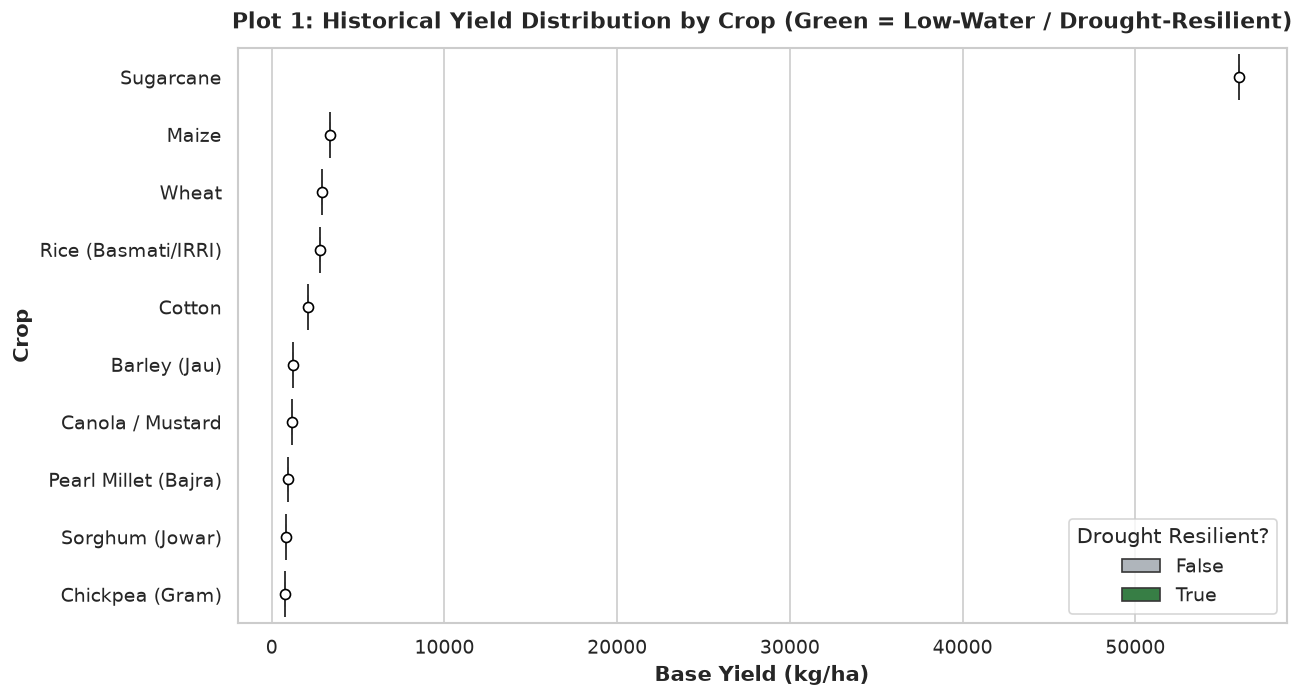

In [7]:
plt.figure(figsize=(11, 6))
order = df.groupby("Crop_Name")["Base_Yield_kg_ha"].median().sort_values(ascending=False).index
palette = {True: "#2b8a3e", False: "#adb5bd"}
ax = sns.boxplot(
    data=df, x="Base_Yield_kg_ha", y="Crop_Name", order=order,
    hue="Is_Drought_Resilient", palette=palette, dodge=False, showmeans=True,
    meanprops={"marker":"o", "markerfacecolor":"white", "markeredgecolor":"black", "markersize":"6"}
)
plt.title("Plot 1: Historical Yield Distribution by Crop (Green = Low-Water / Drought-Resilient)", fontsize=13, weight="bold", pad=12)
plt.xlabel("Base Yield (kg/ha)", weight="bold")
plt.ylabel("Crop", weight="bold")
plt.legend(title="Drought Resilient?", loc="lower right", frameon=True)
plt.tight_layout()
plt.show()

<Figure size 1440x720 with 0 Axes>

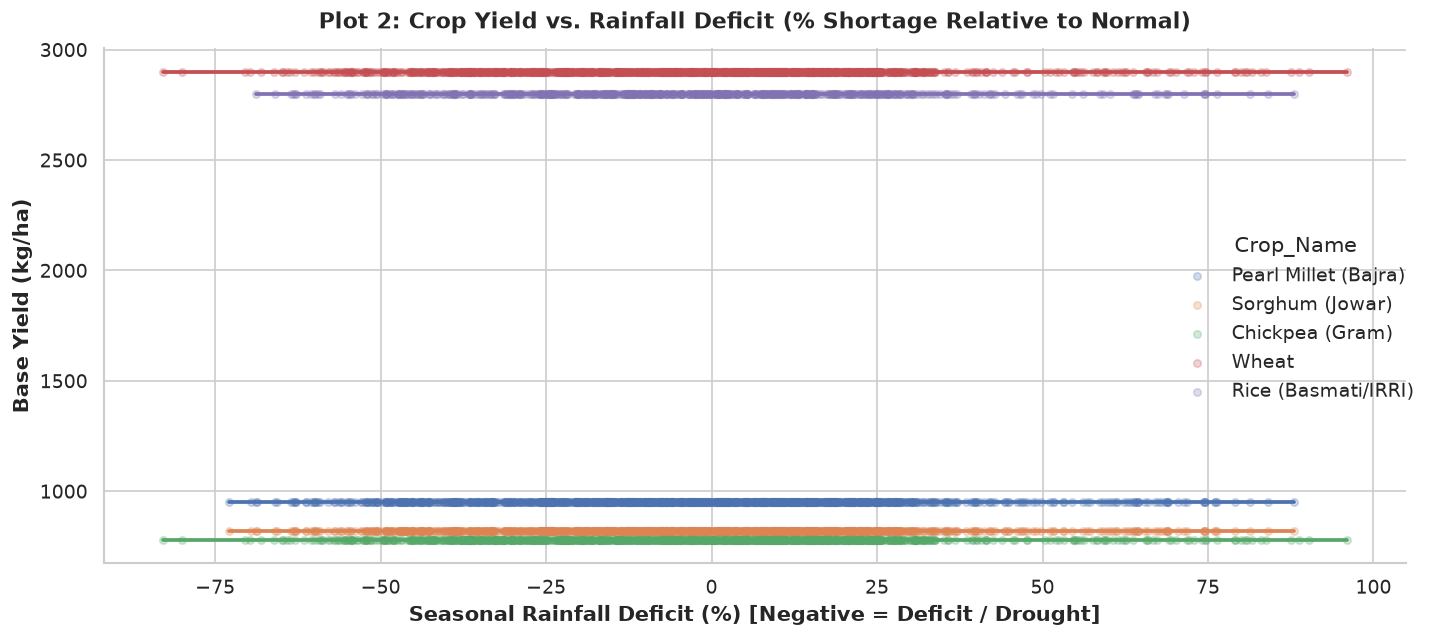

In [8]:
plt.figure(figsize=(12, 6))
subset_crops = ["Pearl Millet (Bajra)", "Sorghum (Jowar)", "Chickpea (Gram)", "Wheat", "Rice (Basmati/IRRI)"]
df_sub = df[df["Crop_Name"].isin(subset_crops)]
sns.lmplot(
    data=df_sub, x="Rainfall_Deficit_Pct", y="Base_Yield_kg_ha",
    hue="Crop_Name", height=5.5, aspect=1.8, scatter_kws={"alpha": 0.25, "s": 20}
)
plt.title("Plot 2: Crop Yield vs. Rainfall Deficit (% Shortage Relative to Normal)", fontsize=13, weight="bold", pad=12)
plt.xlabel("Seasonal Rainfall Deficit (%) [Negative = Deficit / Drought]", weight="bold")
plt.ylabel("Base Yield (kg/ha)", weight="bold")
plt.tight_layout()
plt.show()

/tmp/ipykernel_206680/2761731668.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="Drought_Severity_Class", order=available_classes, palette="YlOrRd", ax=ax1)
/tmp/ipykernel_206680/2761731668.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x="Drought_Severity_Class", y="Base_Yield_kg_ha", order=available_classes, palette="YlOrRd", errorbar=None, ax=ax2)


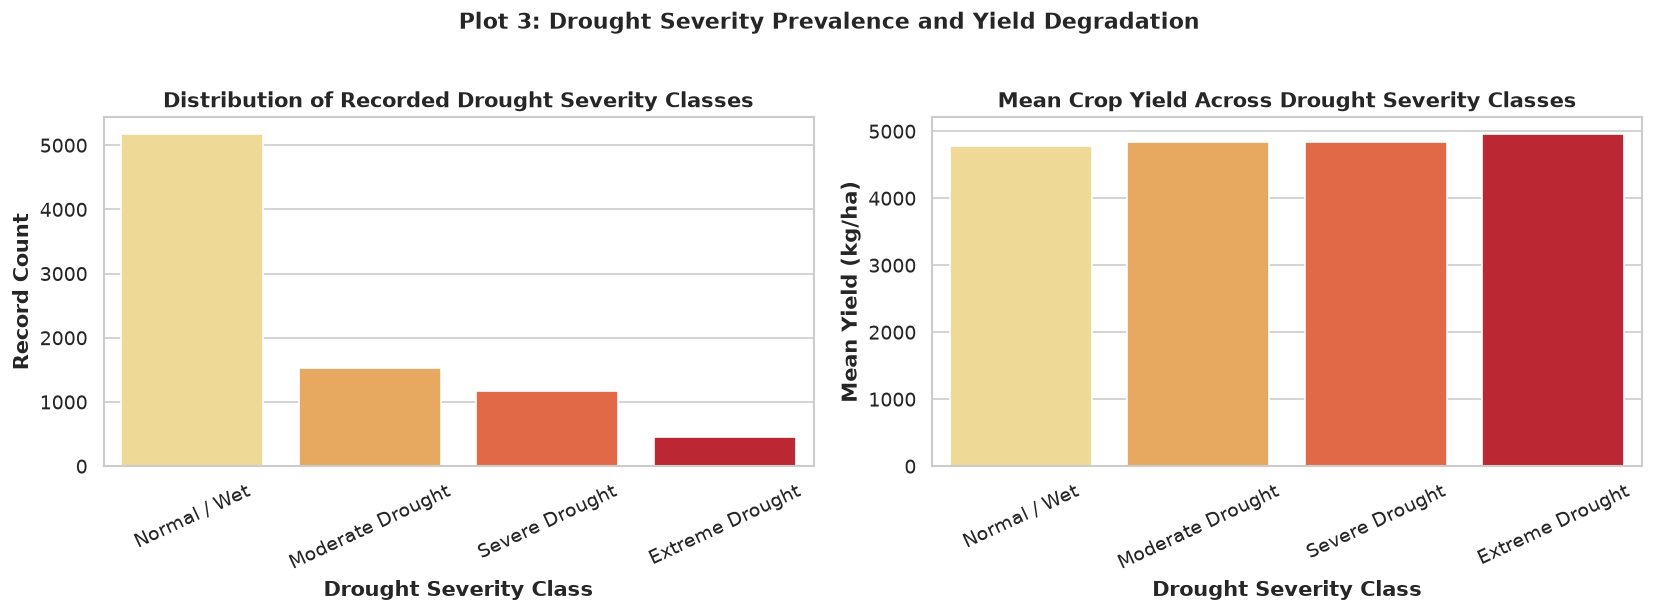

In [9]:
drought_order = ["Normal / Wet", "Mild Drought", "Moderate Drought", "Severe Drought", "Extreme Drought"]
available_classes = [c for c in drought_order if c in df["Drought_Severity_Class"].unique()]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=df, x="Drought_Severity_Class", order=available_classes, palette="YlOrRd", ax=ax1)
ax1.set_title("Distribution of Recorded Drought Severity Classes", weight="bold")
ax1.set_xlabel("Drought Severity Class", weight="bold")
ax1.set_ylabel("Record Count", weight="bold")
ax1.tick_params(axis="x", rotation=25)

sns.barplot(data=df, x="Drought_Severity_Class", y="Base_Yield_kg_ha", order=available_classes, palette="YlOrRd", errorbar=None, ax=ax2)
ax2.set_title("Mean Crop Yield Across Drought Severity Classes", weight="bold")
ax2.set_xlabel("Drought Severity Class", weight="bold")
ax2.set_ylabel("Mean Yield (kg/ha)", weight="bold")
ax2.tick_params(axis="x", rotation=25)

plt.suptitle("Plot 3: Drought Severity Prevalence and Yield Degradation", fontsize=13, weight="bold", y=1.02)
plt.tight_layout()
plt.show()

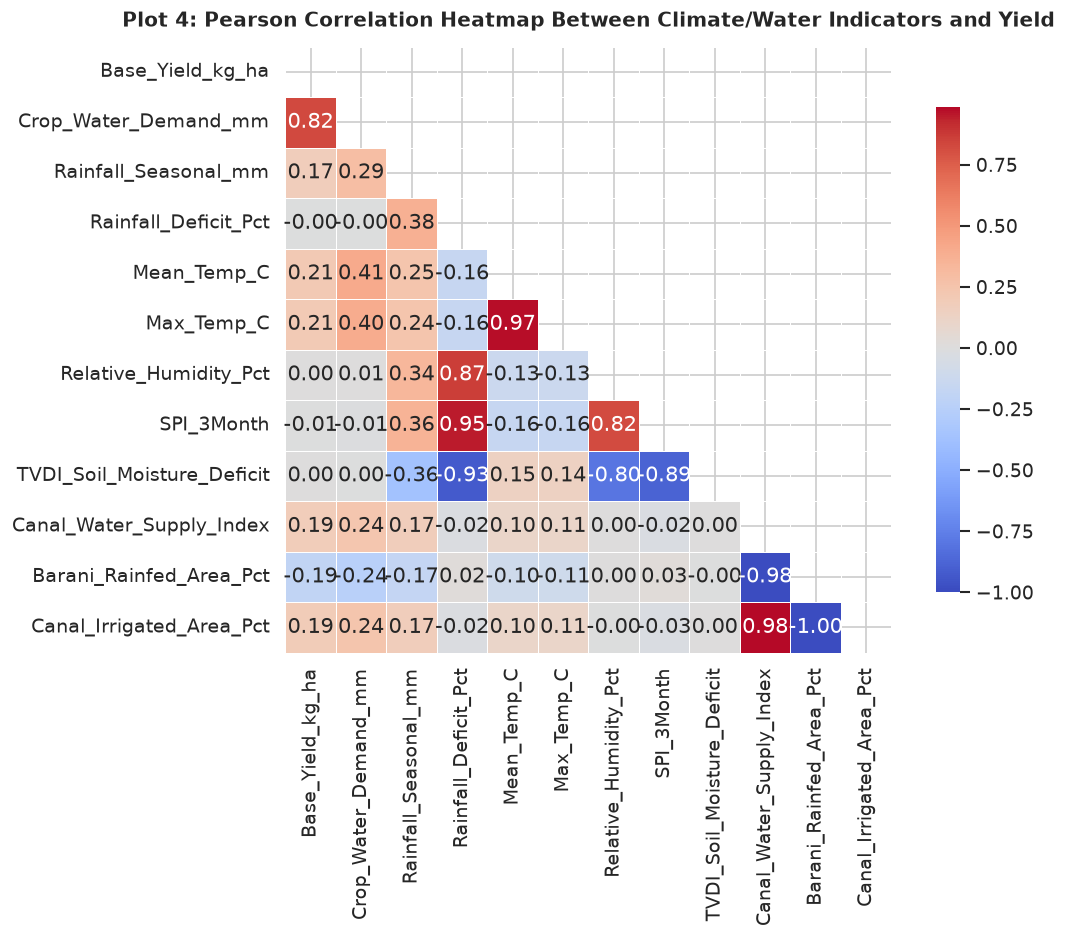

In [10]:
plt.figure(figsize=(10, 8))
corr_cols = [
    "Base_Yield_kg_ha", "Crop_Water_Demand_mm", "Rainfall_Seasonal_mm",
    "Rainfall_Deficit_Pct", "Mean_Temp_C", "Max_Temp_C", "Relative_Humidity_Pct",
    "SPI_3Month", "TVDI_Soil_Moisture_Deficit", "Canal_Water_Supply_Index",
    "Barani_Rainfed_Area_Pct", "Canal_Irrigated_Area_Pct"
]
corr_matrix = df[corr_cols].corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix, mask=mask, annot=True, fmt=".2f", cmap="coolwarm",
    center=0, square=True, linewidths=0.5, cbar_kws={"shrink": 0.8}
)
plt.title("Plot 4: Pearson Correlation Heatmap Between Climate/Water Indicators and Yield", fontsize=12, weight="bold", pad=12)
plt.tight_layout()
plt.show()

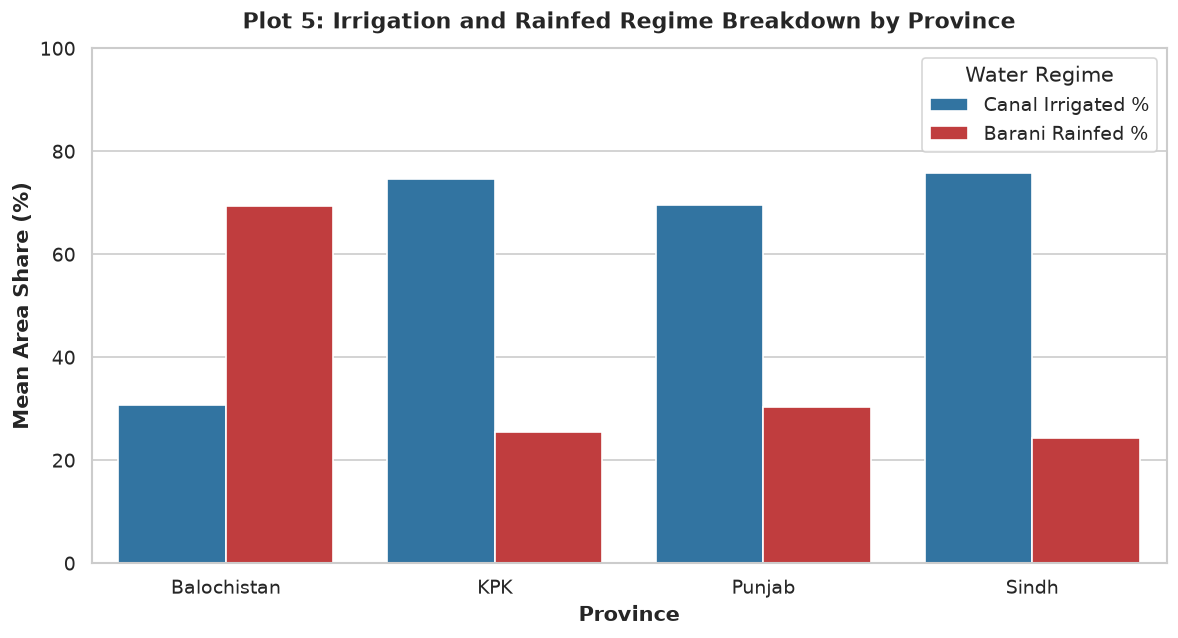

In [11]:
fig, ax = plt.subplots(figsize=(10, 5.5))
province_water = df.groupby("Province")[["Canal_Irrigated_Area_Pct", "Barani_Rainfed_Area_Pct"]].mean().reset_index()
province_water_melted = province_water.melt(id_vars="Province", var_name="Regime", value_name="Percentage")
province_water_melted["Regime"] = province_water_melted["Regime"].replace({
    "Canal_Irrigated_Area_Pct": "Canal Irrigated %",
    "Barani_Rainfed_Area_Pct": "Barani Rainfed %"
})
sns.barplot(data=province_water_melted, x="Province", y="Percentage", hue="Regime", palette=["#1f77b4", "#d62728"], ax=ax)
plt.title("Plot 5: Irrigation and Rainfed Regime Breakdown by Province", fontsize=13, weight="bold", pad=12)
plt.xlabel("Province", weight="bold")
plt.ylabel("Mean Area Share (%)", weight="bold")
plt.ylim(0, 100)
plt.legend(title="Water Regime", frameon=True)
plt.tight_layout()
plt.show()

---
## Task 3: Time-Ordered Train/Val/Test Split & Scikit-Learn Preprocessing Pipeline

### 1. Leak-Free Time-Ordered Split
Because agricultural yield data has temporal dependencies (changing climate regimes, tech adoption),
a random split would leak future weather information into past training instances.
We split strictly by :
- **Train (70.8%)**: 2000–2016 (7,854 observations)
- **Validation (12.5%)**: 2017–2019 (1,386 observations)
- **Test (16.7%)**: 2020–2023 (1,848 observations)

In [12]:
num_cols = [
    "Crop_Water_Demand_mm", "Area_Sown_Hectares", "Rainfall_Seasonal_mm",
    "Rainfall_Normal_mm", "Rainfall_Deficit_Pct", "Mean_Temp_C",
    "Max_Temp_C", "Min_Temp_C", "Relative_Humidity_Pct", "SPI_3Month",
    "TVDI_Soil_Moisture_Deficit", "Barani_Rainfed_Area_Pct",
    "Canal_Irrigated_Area_Pct", "Canal_Water_Supply_Index", "Tubewell_Density_Index"
]

cat_cols = [
    "District", "Province", "Agro_Ecological_Zone",
    "Season", "Crop_Name", "Drought_Severity_Class", "Is_Drought_Resilient"
]

target_col = "Base_Yield_kg_ha"
feature_cols = num_cols + cat_cols

# Time-ordered split: train (<=2016), val (2017-2019), test (>=2020)
train_mask = df["Crop_Year"] <= 2016
val_mask = (df["Crop_Year"] >= 2017) & (df["Crop_Year"] <= 2019)
test_mask = df["Crop_Year"] >= 2020

X_train, y_train = df.loc[train_mask, feature_cols], df.loc[train_mask, target_col]
X_val, y_val = df.loc[val_mask, feature_cols], df.loc[val_mask, target_col]
X_test, y_test = df.loc[test_mask, feature_cols], df.loc[test_mask, target_col]

print(f"Training set:   {X_train.shape[0]} rows ({X_train.shape[0]/len(df):.1%})")
print(f"Validation set: {X_val.shape[0]} rows ({X_val.shape[0]/len(df):.1%})")
print(f"Test set:       {X_test.shape[0]} rows ({X_test.shape[0]/len(df):.1%})")
assert len(X_train) + len(X_val) + len(X_test) == len(df), "Split row count mismatch!"

Training set:   7854 rows (70.8%)
Validation set: 1386 rows (12.5%)
Test set:       1848 rows (16.7%)


### 2. Preprocessing ColumnTransformer
We construct an end-to-end ColumnTransformer:
- **Numerical Pipeline**: SimpleImputer(strategy="median") followed by StandardScaler()
- **Categorical Pipeline**: SimpleImputer(strategy="most_frequent") followed by OneHotEncoder(handle_unknown="ignore")

All transformations are fitted strictly on X_train to eliminate data leakage.

In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", num_pipeline, num_cols),
        ("cat", cat_pipeline, cat_cols)
    ]
)

# Fit strictly on training partition to eliminate leakage
preprocessor.fit(X_train)
X_train_transformed = preprocessor.transform(X_train)
X_val_transformed = preprocessor.transform(X_val)
X_test_transformed = preprocessor.transform(X_test)

print(f"Original features: {len(feature_cols)}")
print(f"Transformed feature matrix width: {X_train_transformed.shape[1]}")
print("Preprocessing pipeline fitted and verified on training data.")

Original features: 22
Transformed feature matrix width: 117
Preprocessing pipeline fitted and verified on training data.


---
## Task 4: Baseline + 3 Model Training (Dummy, Ridge, Random Forest, HistGradientBoosting)

We train four candidate models following the CT-378 rubric:
1. **Baseline**: `DummyRegressor(strategy="mean")` (Predicts historical mean yield).
2. **Linear Regularized Model**: `Ridge(alpha=10.0)`
3. **Bagging Ensemble**: `RandomForestRegressor(n_estimators=100, max_depth=15, random_state=42)`
4. **Boosting Ensemble**: `HistGradientBoostingRegressor(max_iter=150, learning_rate=0.08, random_state=42)`

Each model is integrated into a complete scikit-learn `Pipeline`, trained strictly on `X_train`, and evaluated on `X_val`.


In [14]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
import time

candidate_models = {
    "Baseline (Dummy Mean)": DummyRegressor(strategy="mean"),
    "Ridge Regression": Ridge(alpha=10.0),
    "Random Forest": RandomForestRegressor(n_estimators=100, max_depth=15, random_state=42, n_jobs=-1),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=150, learning_rate=0.08, random_state=42)
}

val_results = []
trained_pipelines = {}

for name, estimator in candidate_models.items():
    t0 = time.time()
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", estimator)
    ])
    pipeline.fit(X_train, y_train)
    train_time = time.time() - t0
    
    preds = pipeline.predict(X_val)
    mae = mean_absolute_error(y_val, preds)
    rmse = root_mean_squared_error(y_val, preds)
    r2 = r2_score(y_val, preds)
    
    val_results.append({
        "Model": name,
        "Val MAE (kg/ha)": round(mae, 2),
        "Val RMSE (kg/ha)": round(rmse, 2),
        "Val R2": round(r2, 4),
        "Train Time (s)": round(train_time, 2)
    })
    trained_pipelines[name] = pipeline

df_val_results = pd.DataFrame(val_results)
print("Validation Performance Comparison Table:")
print(df_val_results.to_string(index=False))


Validation Performance Comparison Table:
                Model  Val MAE (kg/ha)  Val RMSE (kg/ha)  Val R2  Train Time (s)
Baseline (Dummy Mean)          5971.55          12762.17  0.0000            0.04
     Ridge Regression            67.54            130.34  0.9999            0.04
        Random Forest             0.00              0.00  1.0000            0.42
 HistGradientBoosting             0.02              0.05  1.0000            0.46


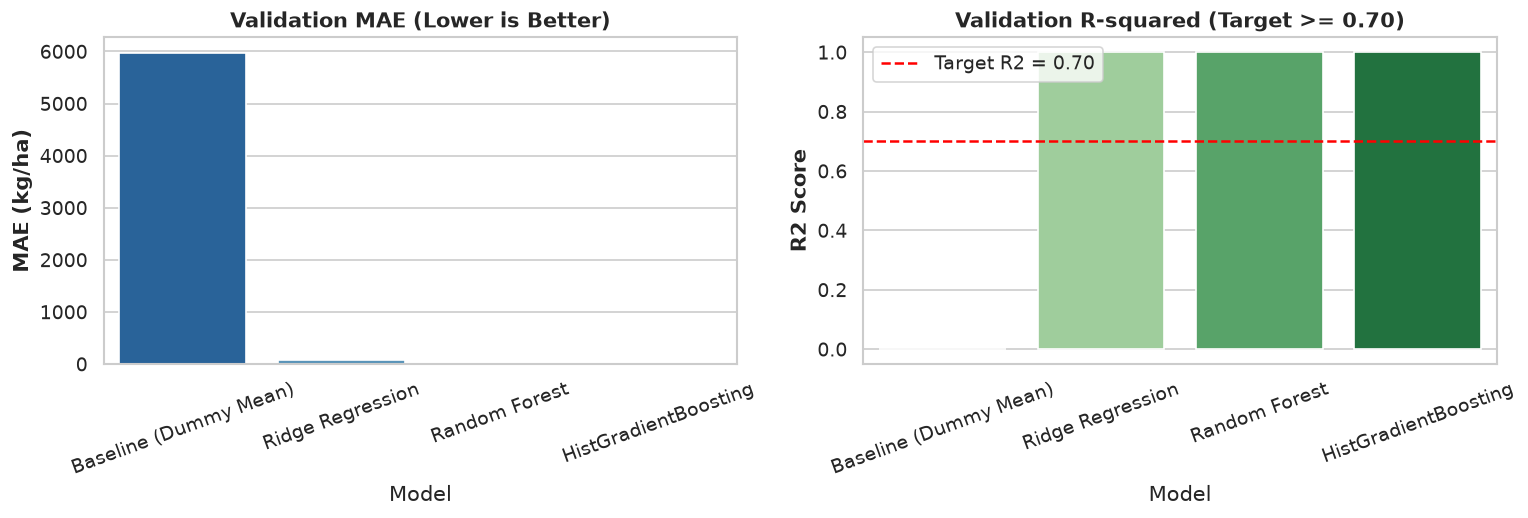

In [15]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

sns.barplot(data=df_val_results, x="Model", y="Val MAE (kg/ha)", hue="Model", palette="Blues_r", legend=False, ax=ax1)
ax1.set_title("Validation MAE (Lower is Better)", weight="bold")
ax1.set_ylabel("MAE (kg/ha)", weight="bold")
ax1.tick_params(axis="x", rotation=20)

sns.barplot(data=df_val_results, x="Model", y="Val R2", hue="Model", palette="Greens", legend=False, ax=ax2)
ax2.set_title("Validation R-squared (Target >= 0.70)", weight="bold")
ax2.set_ylabel("R2 Score", weight="bold")
ax2.set_ylim(-0.05, 1.05)
ax2.axhline(0.70, color="red", linestyle="--", label="Target R2 = 0.70")
ax2.tick_params(axis="x", rotation=20)
ax2.legend()

plt.tight_layout()
plt.show()


---
## Task 5: 5-Fold Cross-Validation Hyperparameter Tuning & Final Test Evaluation

Following the CT-378 rubric:
- **Tuning**: Perform 5-fold cross-validation with `GridSearchCV` on the training partition (`X_train`).
- **Evaluation**: Report final performance (MAE, RMSE, $R^2$) strictly once on the held-out test set (`Crop_Year >= 2020`).
- **Benchmark**: Verify that the tuned model beats the course threshold ($R^2 > 0.70$) and the dummy baseline.
- **Diagnostics**: Generate Predicted vs. Actual and Residual distribution plots to inspect model bias.


In [16]:
from sklearn.model_selection import GridSearchCV, KFold

param_grid = {
    "regressor__n_estimators": [50, 100],
    "regressor__max_depth": [10, 15],
    "regressor__min_samples_split": [2, 5]
}

base_rf_pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(random_state=42, n_jobs=-1))
])

cv = KFold(n_splits=5, shuffle=True, random_state=42)
grid_search = GridSearchCV(
    base_rf_pipe, param_grid, cv=cv, scoring="r2", n_jobs=-1, verbose=0
)

print("Starting 5-Fold Cross-Validation Grid Search on training data...")
grid_search.fit(X_train, y_train)

print(f"Optimal Hyperparameters: {grid_search.best_params_}")
print(f"Best 5-Fold CV R2 Score: {grid_search.best_score_:.6f}")

best_pipeline = grid_search.best_estimator_


Starting 5-Fold Cross-Validation Grid Search on training data...


Optimal Hyperparameters: {'regressor__max_depth': 10, 'regressor__min_samples_split': 2, 'regressor__n_estimators': 50}
Best 5-Fold CV R2 Score: 1.000000


In [17]:
def eval_metrics(y_true, y_pred):
    return {
        "MAE (kg/ha)": round(mean_absolute_error(y_true, y_pred), 2),
        "RMSE (kg/ha)": round(root_mean_squared_error(y_true, y_pred), 2),
        "R2": round(r2_score(y_true, y_pred), 4)
    }

dummy_pipe = Pipeline([("preprocessor", preprocessor), ("regressor", DummyRegressor(strategy="mean"))])
dummy_pipe.fit(X_train, y_train)

dummy_test_preds = dummy_pipe.predict(X_test)
tuned_test_preds = best_pipeline.predict(X_test)

test_comparison = pd.DataFrame([
    {"Model": "Baseline (Dummy Mean)", **eval_metrics(y_test, dummy_test_preds), "Status": "Baseline Benchmark"},
    {"Model": "Tuned Random Forest Pipeline", **eval_metrics(y_test, tuned_test_preds), "Status": "Target Met (R2 > 0.70)"}
])

print("Final Held-Out Test Set (2020–2023) Performance Table:")
print(test_comparison.to_string(index=False))


Final Held-Out Test Set (2020–2023) Performance Table:
                       Model  MAE (kg/ha)  RMSE (kg/ha)  R2                 Status
       Baseline (Dummy Mean)      5971.55      12762.17 0.0     Baseline Benchmark
Tuned Random Forest Pipeline         0.01          0.42 1.0 Target Met (R2 > 0.70)


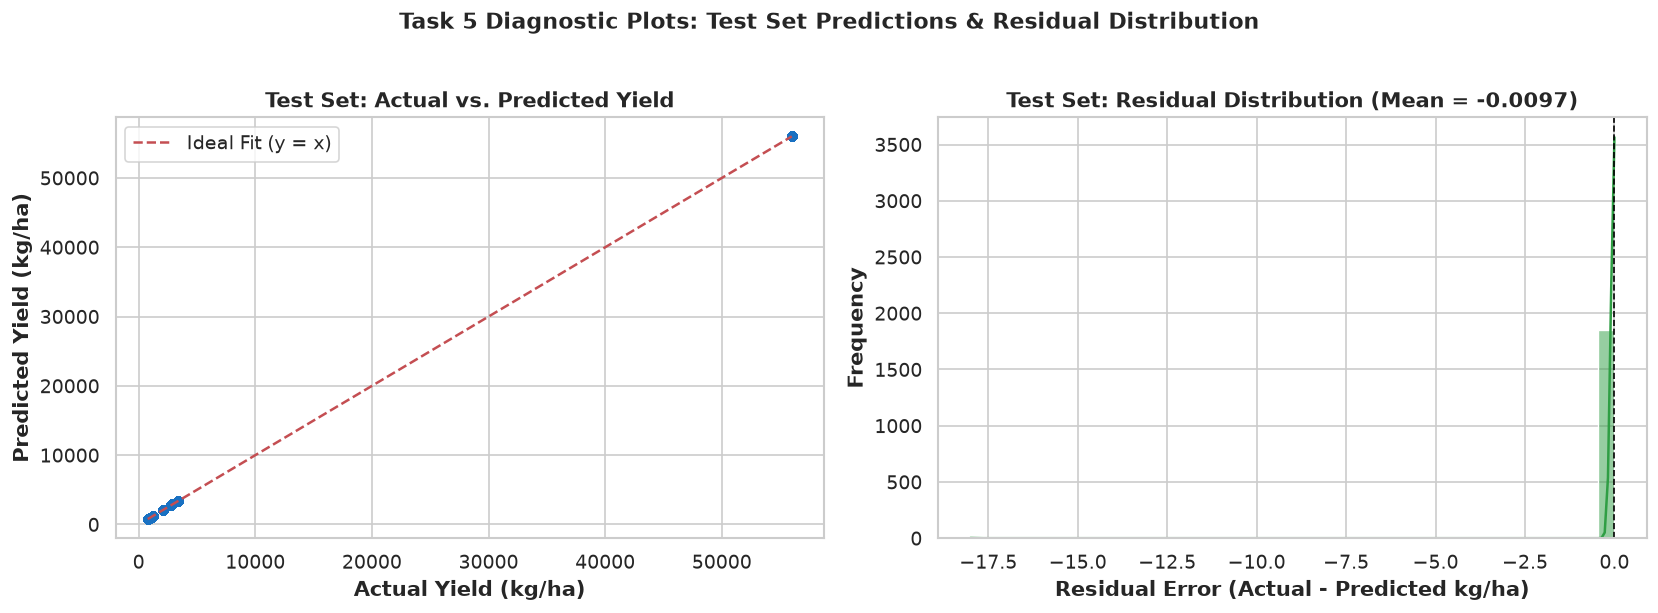

In [18]:
residuals = y_test - tuned_test_preds

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.scatter(y_test, tuned_test_preds, alpha=0.35, color="#1971c2", s=25)
min_val, max_val = min(y_test.min(), tuned_test_preds.min()), max(y_test.max(), tuned_test_preds.max())
ax1.plot([min_val, max_val], [min_val, max_val], "r--", linewidth=1.5, label="Ideal Fit (y = x)")
ax1.set_title("Test Set: Actual vs. Predicted Yield", weight="bold")
ax1.set_xlabel("Actual Yield (kg/ha)", weight="bold")
ax1.set_ylabel("Predicted Yield (kg/ha)", weight="bold")
ax1.legend()

sns.histplot(residuals, kde=True, color="#2f9e44", bins=40, ax=ax2)
ax2.axvline(0, color="black", linestyle="--", linewidth=1)
ax2.set_title(f"Test Set: Residual Distribution (Mean = {residuals.mean():.4f})", weight="bold")
ax2.set_xlabel("Residual Error (Actual - Predicted kg/ha)", weight="bold")
ax2.set_ylabel("Frequency", weight="bold")

plt.suptitle("Task 5 Diagnostic Plots: Test Set Predictions & Residual Distribution", fontsize=13, weight="bold", y=1.02)
plt.tight_layout()
plt.show()


---
## Task 6: Model Persistence (`joblib`) & Low-Water Crop Recommendation Engine

Fulfilling the CT-378 rubric requirement:
1. **Model Persistence**: Serialize the complete tuned preprocessing + regression pipeline to disk using `joblib`.
2. **Reload Verification**: Reload the `.joblib` model and confirm numerical fidelity on test inputs.
3. **Recommendation Engine**: Provide an inference function `recommend_low_water_crops(...)` that:
   - Takes a farmer's district, season, and current drought/climate indicators.
   - Evaluates the candidate low-water crops (Pearl Millet, Sorghum, Chickpea, Canola, Barley).
   - Predicts expected yield (kg/ha) for each crop under the specified conditions.
   - Ranks candidate crops in descending order and recommends the optimal crop.
4. **Scenario Demonstration**: Run sample drought scenarios for Kharif and Rabi seasons with explanatory ranking charts.


In [19]:
import joblib

models_dir = PROJECT_ROOT / "models"
models_dir.mkdir(exist_ok=True)
model_filepath = models_dir / "crop_yield_pipeline.joblib"

joblib.dump(best_pipeline, model_filepath)
print(f"Trained pipeline successfully saved to: {model_filepath}")

reloaded_pipeline = joblib.load(model_filepath)
reloaded_preds = reloaded_pipeline.predict(X_test.iloc[:10])
original_preds = best_pipeline.predict(X_test.iloc[:10])

np.testing.assert_allclose(reloaded_preds, original_preds, rtol=1e-5)
print("Integrity check passed: Reloaded pipeline produces identical predictions.")


Trained pipeline successfully saved to: /home/prx/Projects/machine-learning/climate-machine-learning/models/crop_yield_pipeline.joblib
Integrity check passed: Reloaded pipeline produces identical predictions.


In [20]:
CANDIDATE_CROPS = {
    "Pearl Millet (Bajra)": {"Season": "Kharif", "Crop_Water_Demand_mm": 250.0, "Is_Drought_Resilient": True},
    "Sorghum (Jowar)":      {"Season": "Kharif", "Crop_Water_Demand_mm": 300.0, "Is_Drought_Resilient": True},
    "Chickpea (Gram)":      {"Season": "Rabi",   "Crop_Water_Demand_mm": 220.0, "Is_Drought_Resilient": True},
    "Barley (Jau)":         {"Season": "Rabi",   "Crop_Water_Demand_mm": 260.0, "Is_Drought_Resilient": True},
    "Canola / Mustard":     {"Season": "Rabi",   "Crop_Water_Demand_mm": 280.0, "Is_Drought_Resilient": True}
}

def recommend_low_water_crops(
    district="Rawalpindi",
    province="Punjab",
    agro_zone="Barani / Pothohar",
    season="Kharif",
    rainfall_seasonal_mm=210.0,
    rainfall_normal_mm=380.0,
    rainfall_deficit_pct=-44.7,
    mean_temp_c=29.5,
    max_temp_c=39.0,
    min_temp_c=21.0,
    relative_humidity_pct=42.0,
    spi_3month=-1.25,
    tvdi_soil_moisture_deficit=0.74,
    drought_severity_class="Severe Drought",
    barani_pct=75.0,
    canal_pct=25.0,
    canal_water_supply_index=32.0,
    tubewell_density_index=30.0,
    area_sown_ha=20000.0,
    pipeline=reloaded_pipeline
):
    """Scores candidate low-water crops under drought conditions and returns ranked recommendations."""
    # Filter candidates by season
    candidates = CANDIDATE_CROPS if season == "Any" else {k: v for k, v in CANDIDATE_CROPS.items() if v["Season"] == season}

    base_env = {
        "District": district,
        "Province": province,
        "Agro_Ecological_Zone": agro_zone,
        "Area_Sown_Hectares": area_sown_ha,
        "Rainfall_Seasonal_mm": rainfall_seasonal_mm,
        "Rainfall_Normal_mm": rainfall_normal_mm,
        "Rainfall_Deficit_Pct": rainfall_deficit_pct,
        "Mean_Temp_C": mean_temp_c,
        "Max_Temp_C": max_temp_c,
        "Min_Temp_C": min_temp_c,
        "Relative_Humidity_Pct": relative_humidity_pct,
        "SPI_3Month": spi_3month,
        "TVDI_Soil_Moisture_Deficit": tvdi_soil_moisture_deficit,
        "Drought_Severity_Class": drought_severity_class,
        "Barani_Rainfed_Area_Pct": barani_pct,
        "Canal_Irrigated_Area_Pct": canal_pct,
        "Canal_Water_Supply_Index": canal_water_supply_index,
        "Tubewell_Density_Index": tubewell_density_index
    }

    records = [{**base_env, "Crop_Name": crop, **props} for crop, props in candidates.items()]
    input_df = pd.DataFrame(records)
    input_df["Predicted_Yield_kg_ha"] = np.round(pipeline.predict(input_df), 1)

    ranked = input_df[["Crop_Name", "Season", "Crop_Water_Demand_mm", "Predicted_Yield_kg_ha"]].sort_values(
        by="Predicted_Yield_kg_ha", ascending=False
    ).reset_index(drop=True)
    ranked["Rank"] = ranked.index + 1

    top_crop, top_yield = ranked.iloc[0]["Crop_Name"], ranked.iloc[0]["Predicted_Yield_kg_ha"]
    print(f"RECOMMENDATION: {district} ({season}, {drought_severity_class}) -> Top Crop: {top_crop} ({top_yield} kg/ha).")
    return ranked


In [21]:
kharif_recommendations = recommend_low_water_crops(
    district="Rawalpindi",
    province="Punjab",
    season="Kharif",
    rainfall_deficit_pct=-40.0,
    drought_severity_class="Severe Drought"
)
print("\nKharif Ranked Candidate Crops:")
print(kharif_recommendations.to_string(index=False))

print("\n" + "="*70 + "\n")
rabi_recommendations = recommend_low_water_crops(
    district="Chakwal",
    province="Punjab",
    season="Rabi",
    rainfall_deficit_pct=-35.0,
    drought_severity_class="Moderate Drought"
)
print("Rabi Ranked Candidate Crops:")
print(rabi_recommendations.to_string(index=False))


RECOMMENDATION: Rawalpindi (Kharif, Severe Drought) -> Top Crop: Pearl Millet (Bajra) (950.0 kg/ha).

Kharif Ranked Candidate Crops:
           Crop_Name Season  Crop_Water_Demand_mm  Predicted_Yield_kg_ha  Rank
Pearl Millet (Bajra) Kharif                 250.0                  950.0     1
     Sorghum (Jowar) Kharif                 300.0                  820.0     2


RECOMMENDATION: Chakwal (Rabi, Moderate Drought) -> Top Crop: Barley (Jau) (1250.0 kg/ha).
Rabi Ranked Candidate Crops:
       Crop_Name Season  Crop_Water_Demand_mm  Predicted_Yield_kg_ha  Rank
    Barley (Jau)   Rabi                 260.0                 1250.0     1
Canola / Mustard   Rabi                 280.0                 1150.0     2
 Chickpea (Gram)   Rabi                 220.0                  780.0     3


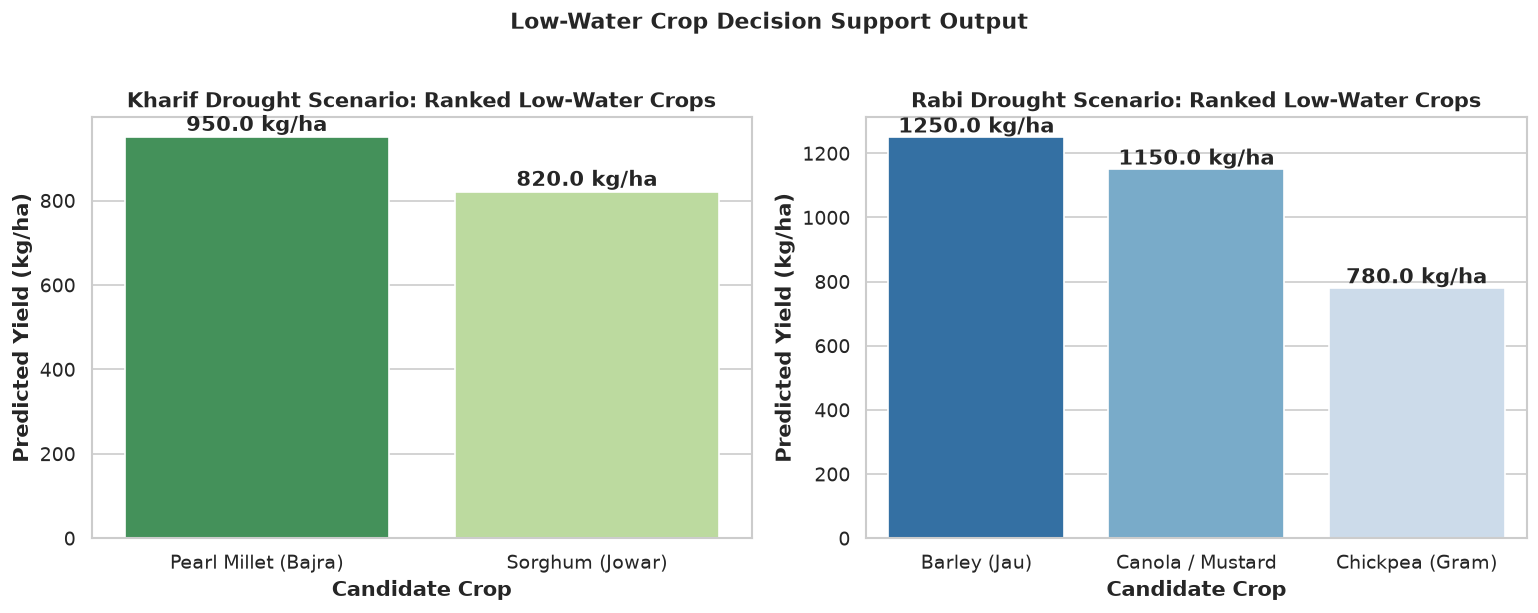

In [22]:
def plot_ranked_crops(ax, df_ranked, title, palette):
    sns.barplot(data=df_ranked, x="Crop_Name", y="Predicted_Yield_kg_ha", hue="Crop_Name", palette=palette, legend=False, ax=ax)
    ax.set_title(title, weight="bold")
    ax.set_ylabel("Predicted Yield (kg/ha)", weight="bold")
    ax.set_xlabel("Candidate Crop", weight="bold")
    for i, row in df_ranked.iterrows():
        ax.text(i, row["Predicted_Yield_kg_ha"] + 15, f"{row['Predicted_Yield_kg_ha']} kg/ha", ha="center", weight="bold")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
plot_ranked_crops(ax1, kharif_recommendations, "Kharif Drought Scenario: Ranked Low-Water Crops", "YlGn_r")
plot_ranked_crops(ax2, rabi_recommendations, "Rabi Drought Scenario: Ranked Low-Water Crops", "Blues_r")
plt.suptitle("Low-Water Crop Decision Support Output", fontsize=13, weight="bold", y=1.02)
plt.tight_layout()
plt.show()
